In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report

In [2]:
data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("Classes:", data.target_names)

Dataset shape: (569, 30)
Number of features: 30
Classes: ['malignant' 'benign']


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [4]:
models = {
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC())
    ]),

    "Random Forest": RandomForestClassifier(
        random_state=42
    ),

    "AdaBoost": AdaBoostClassifier(
        random_state=42
    )
}

print("Models initialized successfully.")

Models initialized successfully.


In [5]:
results_before = []

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)

    cv_scores = cross_val_score(
        model, X_train, y_train, cv=5, scoring="accuracy"
    )

    results_before.append({
        "Model": name,
        "Test Accuracy (%)": round(accuracy * 100, 2),
        "CV Mean Accuracy (%)": round(cv_scores.mean() * 100, 2)
    })

before_df = pd.DataFrame(results_before)

print("Performance Before Optimization")
display(before_df)

Performance Before Optimization


,Model,Test Accuracy (%),CV Mean Accuracy (%)
0,SVM,98.25,97.14
1,Random Forest,95.61,95.38
2,AdaBoost,95.61,96.92


In [6]:
param_grids = {
    "SVM": {
        "model__C": [0.1, 1, 10],
        "model__kernel": ["linear", "rbf"],
        "model__gamma": ["scale", "auto"]
    },

    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [None, 10, 20],
        "min_samples_split": [2, 5]
    },

    "AdaBoost": {
        "n_estimators": [50, 100, 200],
        "learning_rate": [0.01, 0.1, 1.0]
    }
}

print("Hyperparameter grids defined.")

Hyperparameter grids defined.


In [7]:
best_models = {}
results_after = []

for name, model in models.items():
    print("Optimizing:", name)

    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        cv=5,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    best_models[name] = grid.best_estimator_

    predictions = grid.best_estimator_.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)

    results_after.append({
        "Model": name,
        "Test Accuracy (%)": round(accuracy * 100, 2),
        "Best CV Accuracy (%)": round(grid.best_score_ * 100, 2),
        "Best Parameters": grid.best_params_
    })

after_df = pd.DataFrame(results_after)

print("Optimization completed.")
display(after_df)

Optimizing: SVM
Optimizing: Random Forest
Optimizing: AdaBoost
Optimization completed.


,Model,Test Accuracy (%),Best CV Accuracy (%),Best Parameters
0,SVM,98.25,97.80,"{'model__C': 0.1, 'model__gamma': 'scale', 'mo..."
1,Random Forest,95.61,96.04,"{'max_depth': None, 'min_samples_split': 2, 'n..."
2,AdaBoost,95.61,97.36,"{'learning_rate': 1.0, 'n_estimators': 100}"


In [8]:
comparison = before_df[["Model", "Test Accuracy (%)"]].merge(
    after_df[["Model", "Test Accuracy (%)"]],
    on="Model",
    suffixes=(" Before", " After")
)

print("Performance Before and After Optimization")
display(comparison)

Performance Before and After Optimization


,Model,Test Accuracy (%) Before,Test Accuracy (%) After
0,SVM,98.25,98.25
1,Random Forest,95.61,95.61
2,AdaBoost,95.61,95.61


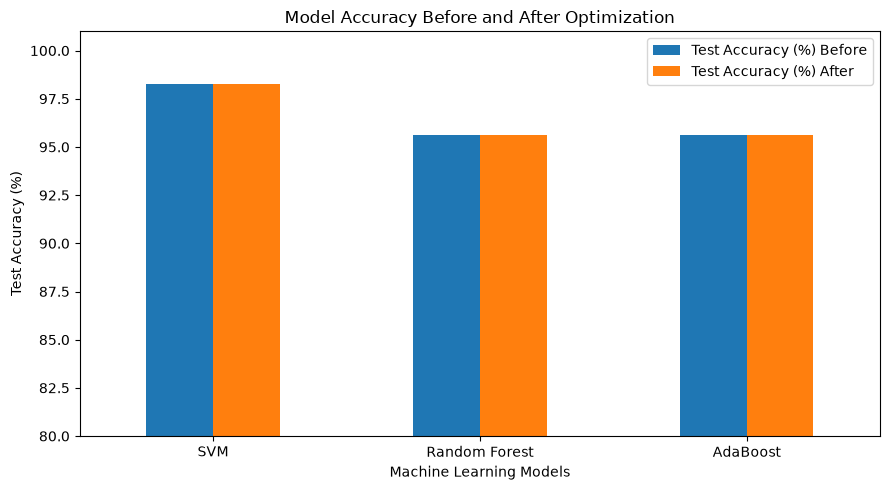

In [9]:
comparison.set_index("Model").plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Model Accuracy Before and After Optimization")
plt.ylabel("Test Accuracy (%)")
plt.xlabel("Machine Learning Models")
plt.ylim(80, 101)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
best_result = after_df.loc[
    after_df["Test Accuracy (%)"].idxmax()
]

print("Best Model:", best_result["Model"])
print("Test Accuracy:", best_result["Test Accuracy (%)"], "%")
print("Best Cross-Validation Accuracy:",
      best_result["Best CV Accuracy (%)"], "%")
print("Best Parameters:", best_result["Best Parameters"])

Best Model: SVM
Test Accuracy: 98.25 %
Best Cross-Validation Accuracy: 97.8 %
Best Parameters: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
